# T12. Patrones temporales y viajes simultáneos

**Objetivo.** Describir cuándo se viaja (por día, por hora y por tipo de día) y cuántos patinetes están en uso a la vez.

**Valor para el proyecto.** Fija las franjas horarias y los tipos de día con los que se construyen las matrices OD y se ejecuta el simulador, dice si la semana reservada es comparable con el periodo de ajuste y da una cota inferior de la flota.

Las cifras que fijan parámetros salen del periodo de ajuste (1–21/02); la semana reservada se describe para compararla. Solo se usan viajes elegibles.

In [1]:
import numpy as np
import pandas as pd
from IPython.display import display

from comun.config import cargar_config, carpeta_tablas
from comun.datos import cargar_viajes
from comun.figuras import guardar_figura, plt
from comun.web import exportar

TEMA, FASE = "exploracion", "fase0"
TABLAS = carpeta_tablas(TEMA)
CFG = cargar_config()
FRANJAS = CFG["exploracion"]["franjas_horarias"]
NOMBRES_FRANJA = {"madrugada": "madrugada", "punta_manana": "punta de mañana", "mediodia": "mediodía",
                  "punta_tarde": "punta de tarde", "noche": "noche"}
DIAS = ["lunes", "martes", "miércoles", "jueves", "viernes", "sábado", "domingo"]
COLORES = {"laborable": "#4C72B0", "fin_de_semana": "#DD8452"}
CORTE = pd.Timestamp(CFG["datos"]["periodos"]["reservada"][0])


def tabla_indicadores(filas):
    # Tabla indicador/valor que conserva los enteros como enteros en el CSV.
    return pd.DataFrame({"indicador": [k for k, _ in filas],
                         "valor": pd.Series([v for _, v in filas], dtype=object)})

v = cargar_viajes()
v["fecha"] = v["tsO"].dt.date
v["hora"] = v["tsO"].dt.hour
v["dia_semana"] = v["tsO"].dt.day_of_week
v["tipo_dia"] = np.where(v["dia_semana"] >= 5, "fin_de_semana", "laborable")
ajuste = v[v["periodo"] == "ajuste"]
print(f"{len(v)} viajes elegibles; {len(ajuste)} en el periodo de ajuste")

23292 viajes elegibles; 16710 en el periodo de ajuste


## 1. Viajes por día

**Qué queremos ver.** La serie diaria del mes, la diferencia entre laborables y fines de semana, la tendencia y los días anómalos.

**Por qué importa.** Si la demanda crece durante el mes, la semana reservada no es una muestra cualquiera: validar la red con ella es más exigente. Los días anómalos se explican con la meteorología (T17) antes de decidir si se quitan.

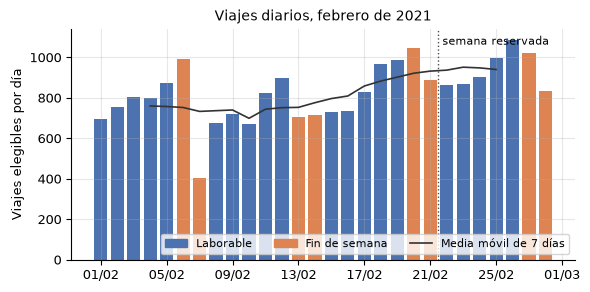

,valor
viajes_dia_media_ajuste,795.7
viajes_dia_media_reservada,940.3
tendencia_ajuste_viajes_por_dia,9.42
dia_minimo,2021-02-07
viajes_dia_minimo,403


In [2]:
diaria = v.groupby("fecha").agg(viajes=("trip_id", "size"), patinetes_activos=("idS", "nunique"),
                                dia_semana=("dia_semana", "first"), tipo_dia=("tipo_dia", "first"),
                                periodo=("periodo", "first"))
diaria["dia_semana"] = diaria["dia_semana"].map(dict(enumerate(DIAS)))
diaria["media_movil"] = diaria["viajes"].rolling(7, center=True).mean().round(1)
diaria.reset_index().to_csv(TABLAS / "T12_viajes_diarios.csv", index=False)

en_ajuste = diaria["periodo"] == "ajuste"
pendiente = np.polyfit(np.arange(en_ajuste.sum()), diaria.loc[en_ajuste, "viajes"].to_numpy(), 1)[0]
volumen = {
    "viajes_dia_media_ajuste": round(diaria.loc[en_ajuste, "viajes"].mean(), 1),
    "viajes_dia_media_reservada": round(diaria.loc[~en_ajuste, "viajes"].mean(), 1),
    "tendencia_ajuste_viajes_por_dia": round(pendiente, 2),
    "dia_minimo": str(diaria["viajes"].idxmin()),
    "viajes_dia_minimo": int(diaria["viajes"].min()),
}

fig, eje = plt.subplots(figsize=(6.5, 3.0))
x = pd.to_datetime(diaria.index)
eje.bar(x, diaria["viajes"], color=[COLORES[t] for t in diaria["tipo_dia"]], width=0.8)
eje.plot(x, diaria["media_movil"], color="0.2", lw=1.2, label="Media móvil de 7 días")
eje.axvline(CORTE - pd.Timedelta(hours=12), color="0.3", ls=":", lw=1)
eje.text(CORTE - pd.Timedelta(hours=12), eje.get_ylim()[1] * 0.97, " semana reservada", fontsize=8, va="top")
asas = [plt.matplotlib.patches.Patch(color=COLORES["laborable"], label="Laborable"),
        plt.matplotlib.patches.Patch(color=COLORES["fin_de_semana"], label="Fin de semana"),
        *eje.get_legend_handles_labels()[0]]
eje.legend(handles=asas, loc="lower right", ncols=3)
eje.set_ylabel("Viajes elegibles por día")
eje.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%d/%m"))
eje.set_title("Viajes diarios, febrero de 2021")
guardar_figura(fig, TEMA, "T12_serie_diaria")

exportar(FASE, "t12_serie_diaria", {"dias": diaria.reset_index(), "corte_reservada": CORTE.date(), **volumen})
display(pd.Series(volumen).to_frame("valor"))

**Conclusiones.**

- En el ajuste hay 795,7 viajes al día de media y en la semana reservada 940,3 (**+18 %**). La tendencia del ajuste es de +9,4 viajes al día por cada día.
- La semana reservada es más exigente que el periodo de ajuste: la red se validará con más demanda de la que se usó para diseñarla, y hay que decirlo en la memoria.
- El día con menos viajes es el domingo 07/02 (403), la mitad que el sábado anterior. Pendiente de cruzarlo con la lluvia en T17.

## 2. Perfil horario por tipo de día y franjas

**Qué queremos ver.** Cuántos viajes salen en cada hora en un laborable medio y en un fin de semana medio, y si las franjas provisionales de `config.yaml` caen donde cambia el perfil.

**Por qué importa.** Las matrices OD y el simulador trabajan por franja y tipo de día. Si los dos tipos de día tuvieran la misma forma bastaría con una matriz; si no, hay que separarlos. Las franjas deben agrupar horas con un comportamiento parecido.

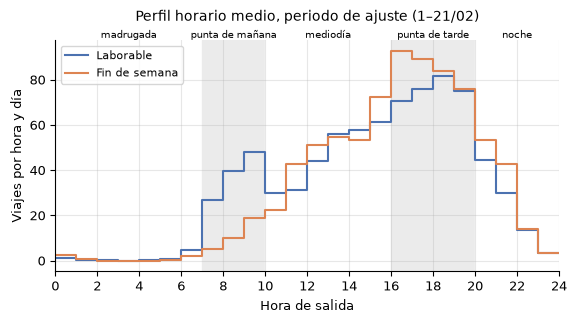

,horas,laborable_viajes_dia,fin_de_semana_viajes_dia,laborable_cuota_pc,fin_de_semana_cuota_pc
franja,,,,,
madrugada,0-7,7.67,5.83,0.97,0.73
punta_manana,7-10,114.60,34.34,14.37,4.33
mediodia,10-16,280.33,296.17,35.17,37.41
punta_tarde,16-20,303.28,341.83,38.03,43.18
noche,20-24,91.47,113.49,11.46,14.34


,valor
viajes_dia_laborable_ajuste,797.3
viajes_dia_fin_de_semana_ajuste,791.7
hora_punta_laborable,18.0
hora_punta_fin_de_semana,16.0
diferencia_perfiles_laborable_finde_pc,12.1


In [3]:
def franja_de_hora(horas):
    resultado = pd.Series(pd.NA, index=horas.index, dtype="string")
    for nombre, (h0, h1) in FRANJAS.items():
        resultado[(horas >= h0) & (horas < h1)] = nombre
    return resultado

dias_por_tipo = ajuste.groupby("tipo_dia")["fecha"].nunique()
perfil = ajuste.groupby(["hora", "tipo_dia"]).size().unstack(fill_value=0).reindex(range(24), fill_value=0)
perfil = perfil / dias_por_tipo
cuotas = perfil / perfil.sum()
tabla_perfil = pd.DataFrame({
    "hora": perfil.index,
    "franja": franja_de_hora(pd.Series(perfil.index)).to_numpy(),
    "laborable_viajes_dia": perfil["laborable"].round(2).to_numpy(),
    "fin_de_semana_viajes_dia": perfil["fin_de_semana"].round(2).to_numpy(),
    "laborable_cuota_pc": (100 * cuotas["laborable"]).round(2).to_numpy(),
    "fin_de_semana_cuota_pc": (100 * cuotas["fin_de_semana"]).round(2).to_numpy(),
})
tabla_perfil.to_csv(TABLAS / "T12_perfil_horario.csv", index=False)

por_franja = tabla_perfil.groupby("franja", sort=False)[
    ["laborable_viajes_dia", "fin_de_semana_viajes_dia", "laborable_cuota_pc", "fin_de_semana_cuota_pc"]
].sum().round(2)
por_franja.insert(0, "horas", [f"{h0}-{h1}" for h0, h1 in FRANJAS.values()])
por_franja.reset_index().to_csv(TABLAS / "T12_franjas.csv", index=False)

media_tipo = diaria[en_ajuste].groupby("tipo_dia")["viajes"].mean()
forma = {
    "viajes_dia_laborable_ajuste": round(media_tipo["laborable"], 1),
    "viajes_dia_fin_de_semana_ajuste": round(media_tipo["fin_de_semana"], 1),
    "hora_punta_laborable": int(perfil["laborable"].idxmax()),
    "hora_punta_fin_de_semana": int(perfil["fin_de_semana"].idxmax()),
    "diferencia_perfiles_laborable_finde_pc": round(100 * 0.5 * (cuotas["laborable"] - cuotas["fin_de_semana"]).abs().sum(), 1),
}

fig, eje = plt.subplots(figsize=(6.5, 3.0))
for i, (nombre, (h0, h1)) in enumerate(FRANJAS.items()):
    eje.axvspan(h0, h1, color="0.92" if i % 2 else "white", zorder=0)
    eje.text((h0 + h1) / 2, 1.0, NOMBRES_FRANJA[nombre], transform=eje.get_xaxis_transform(),
             ha="center", va="bottom", fontsize=7)
for t in ("laborable", "fin_de_semana"):
    eje.step(range(25), list(perfil[t]) + [perfil[t].iloc[-1]], where="post", color=COLORES[t],
             label=t.replace("_", " ").capitalize())
eje.set_xlim(0, 24)
eje.set_xticks(range(0, 25, 2))
eje.set_xlabel("Hora de salida")
eje.set_ylabel("Viajes por hora y día")
eje.legend(loc="upper left")
eje.set_title("Perfil horario medio, periodo de ajuste (1–21/02)", pad=14)
guardar_figura(fig, TEMA, "T12_perfil_horario")

exportar(FASE, "t12_perfil_horario", {
    "horas": list(range(24)), "laborable": perfil["laborable"].round(2), "fin_de_semana": perfil["fin_de_semana"].round(2),
    "franjas": [{"nombre": NOMBRES_FRANJA[n], "desde": h0, "hasta": h1} for n, (h0, h1) in FRANJAS.items()],
    "por_franja": por_franja.reset_index(), **forma,
})
display(por_franja, pd.Series(forma).to_frame("valor"))

**Conclusiones.**

- Laborables y fines de semana tienen el mismo volumen diario (797,3 frente a 791,7 viajes) pero distinta forma: los perfiles difieren en un 12,1 % de los viajes.
- El laborable tiene una punta de mañana de 7 a 10 h (14,4 % de sus viajes frente al 4,3 % en fin de semana) y su máximo a las 18 h. El fin de semana empieza tarde y concentra más en la punta de tarde (43,2 % frente a 38,0 %), con el máximo a las 16 h.
- Las franjas provisionales caen donde cambia el perfil, así que **se fijan como definitivas**. Las matrices OD y el simulador se separan por tipo de día.

## 3. Día de la semana × hora

**Qué queremos ver.** Los viajes medios en cada hora de cada día de la semana, para ver si hay días con un patrón propio dentro de los laborables o del fin de semana.

**Por qué importa.** Comprueba si basta con dos tipos de día o si algún día (por ejemplo el viernes por la noche) se comporta distinto y merecería su propio escenario en el simulador.

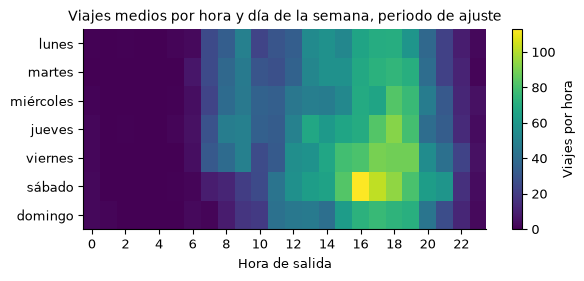

hora,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
lunes,0.7,0.3,0.7,0.0,0.3,1.7,3.0,25.3,33.7,49.3,...,57.3,52.3,66.0,70.0,70.3,59.0,38.3,21.7,9.0,2.3
martes,0.3,0.3,0.0,0.0,0.3,0.3,7.0,25.3,38.3,46.3,...,57.3,57.0,68.0,72.0,74.3,70.7,40.3,21.7,11.3,1.3
miércoles,1.0,0.3,0.0,0.0,0.0,0.7,4.3,23.3,39.3,45.7,...,47.7,52.7,69.0,66.0,82.7,76.7,47.7,31.7,12.0,5.0
jueves,2.0,0.3,0.7,0.0,0.0,1.7,5.0,28.7,48.0,49.0,...,60.7,66.3,69.3,82.7,92.3,79.3,40.3,33.3,13.3,3.7
viernes,2.0,0.3,0.0,0.3,0.3,0.3,4.0,31.7,39.7,49.3,...,66.7,79.0,81.0,89.7,88.7,88.7,55.0,41.7,22.7,5.0
sábado,2.3,0.0,0.0,0.0,0.0,0.7,1.7,9.0,11.7,20.7,...,65.0,82.7,113.0,102.3,94.3,80.7,63.0,59.0,15.7,3.7
domingo,2.3,1.7,0.0,0.0,0.0,0.3,2.7,1.3,8.7,17.3,...,41.3,62.3,72.7,76.0,73.3,71.3,44.0,26.7,12.0,3.0


In [4]:
dias_por_semana = ajuste.groupby("dia_semana")["fecha"].nunique()
calor = ajuste.groupby(["dia_semana", "hora"]).size().unstack(fill_value=0).reindex(columns=range(24), fill_value=0)
calor = calor.div(dias_por_semana, axis=0)
calor.index = [DIAS[d] for d in calor.index]
calor.round(2).to_csv(TABLAS / "T12_calor_dia_hora.csv", index_label="dia_semana")

fig, eje = plt.subplots(figsize=(6.5, 2.6))
im = eje.imshow(calor.to_numpy(), aspect="auto", cmap="viridis")
eje.set_yticks(range(len(calor.index)), calor.index)
eje.set_xticks(range(0, 24, 2))
eje.set_xlabel("Hora de salida")
eje.grid(False)
fig.colorbar(im, ax=eje, label="Viajes por hora")
eje.set_title("Viajes medios por hora y día de la semana, periodo de ajuste")
guardar_figura(fig, TEMA, "T12_calor_dia_hora")

exportar(FASE, "t12_calor", {"dias": list(calor.index), "horas": list(range(24)),
                             "valores": calor.round(2).to_numpy(), "dias_por_semana": dias_por_semana.to_numpy()})
display(calor.round(1))

**Conclusiones.**

- De lunes a viernes el patrón se repite: punta de mañana entre las 8 y las 10 h (máximo de 9 a 10 h), un bajón a media mañana y punta de tarde entre las 17 y las 20 h.
- El sábado no tiene punta de mañana y tiene la tarde más fuerte del periodo (113 viajes de 16 a 17 h). Viernes y sábado son los días con más viajes (unos 915) y el domingo el que menos (670), aunque cada día de la semana solo aparece tres veces en el ajuste y un domingo de lluvia pesa mucho.
- Con tres repeticiones por día no hay base para más tipos de día: se mantienen **laborable y fin de semana**.

## 4. Viajes simultáneos

**Qué queremos ver.** Cuántos viajes hay en curso en cada minuto del mes, su máximo diario y cuántos patinetes distintos se usan cada día.

**Por qué importa.** El máximo de viajes a la vez es una cota inferior de la flota: nunca hacen falta menos patinetes que viajes en curso. Comparado con los 2 331 patinetes del piloto dice si la flota está limitada por el uso simultáneo o por tener los patinetes en el sitio adecuado.

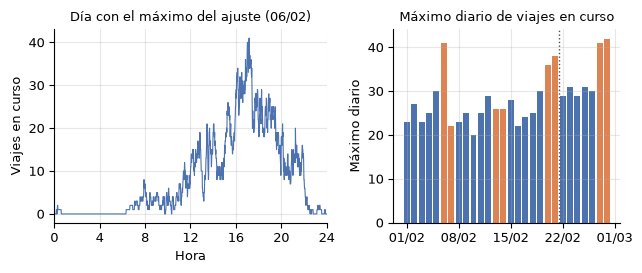

,valor
simultaneos_max_ajuste,41
simultaneos_max_ajuste_dia,2021-02-06
simultaneos_max_ajuste_hora,17:10
simultaneos_max_reservada,42
simultaneos_p99_minutos_ajuste,26.0
patinetes_activos_dia_media_ajuste,486.7
patinetes_activos_dia_max_ajuste,632
patinetes_mes,2305


In [5]:
inicio = v["tsO"].min().floor("D")
fin = v["tsD"].max().ceil("D")
minutos = pd.date_range(inicio, fin, freq="1min", inclusive="left")
salidas = np.sort(v["tsO"].astype("int64").to_numpy())
llegadas = np.sort(v["tsD"].astype("int64").to_numpy())
# En curso en t: ha salido en o antes de t y todavía no ha llegado.
en_curso = pd.Series(np.searchsorted(salidas, minutos.asi8, side="right")
                     - np.searchsorted(llegadas, minutos.asi8, side="right"), index=minutos)

serie = pd.DataFrame({"en_curso": en_curso, "fecha": en_curso.index.date})
simult = serie.groupby("fecha")["en_curso"].agg(maximo="max", media="mean")
simult["hora_maximo"] = serie.groupby("fecha")["en_curso"].idxmax().dt.strftime("%H:%M")
simult["media"] = simult["media"].round(2)
simult = simult.join(diaria[["periodo", "tipo_dia", "patinetes_activos"]])
simult.reset_index().to_csv(TABLAS / "T12_simultaneos_diarios.csv", index=False)

s_ajuste = simult["periodo"] == "ajuste"
dia_max = simult.loc[s_ajuste, "maximo"].idxmax()
simultaneos = {
    "simultaneos_max_ajuste": int(simult.loc[s_ajuste, "maximo"].max()),
    "simultaneos_max_ajuste_dia": str(dia_max),
    "simultaneos_max_ajuste_hora": simult.loc[dia_max, "hora_maximo"],
    "simultaneos_max_reservada": int(simult.loc[~s_ajuste, "maximo"].max()),
    "simultaneos_p99_minutos_ajuste": float(np.percentile(serie.loc[serie["fecha"].map(s_ajuste), "en_curso"], 99)),
    "patinetes_activos_dia_media_ajuste": round(simult.loc[s_ajuste, "patinetes_activos"].mean(), 1),
    "patinetes_activos_dia_max_ajuste": int(simult.loc[s_ajuste, "patinetes_activos"].max()),
    "patinetes_mes": int(v["idS"].nunique()),
}

fig, (a, b) = plt.subplots(1, 2, figsize=(6.5, 2.8), gridspec_kw={"width_ratios": [1.2, 1]})
dia = serie[serie["fecha"] == dia_max]["en_curso"]
a.plot(dia.index.hour + dia.index.minute / 60, dia.to_numpy(), color="#4C72B0", lw=0.8)
a.set_xlim(0, 24)
a.set_xticks(range(0, 25, 4))
a.set_xlabel("Hora")
a.set_ylabel("Viajes en curso")
a.set_title(f"Día con el máximo del ajuste ({pd.Timestamp(dia_max):%d/%m})", fontsize=9)
b.bar(pd.to_datetime(simult.index), simult["maximo"], color=[COLORES[t] for t in simult["tipo_dia"]])
b.axvline(CORTE - pd.Timedelta(hours=12), color="0.3", ls=":", lw=1)
b.xaxis.set_major_locator(plt.matplotlib.dates.DayLocator(bymonthday=[1, 8, 15, 22]))
b.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%d/%m"))
b.set_ylabel("Máximo diario")
b.set_title("Máximo diario de viajes en curso", fontsize=9)
fig.tight_layout()
guardar_figura(fig, TEMA, "T12_simultaneos")

exportar(FASE, "t12_simultaneos", {
    "dias": simult.reset_index(),
    "minutos_por_dia": {str(f): g.to_numpy() for f, g in serie.groupby("fecha")["en_curso"]},
    **simultaneos,
})
display(pd.Series(simultaneos).to_frame("valor"))

**Conclusiones.**

- Como mucho hay **41 viajes en curso a la vez** en el ajuste (sábado 06/02 a las 17:10) y 42 en la semana reservada. En el 99 % de los minutos hay 26 o menos.
- Cada día se usan de media 486,7 patinetes distintos (máximo 632) de los 2 305 que aparecen en viajes elegibles.
- La cota inferior de 41 está muy lejos de la flota observada: **el tamaño de flota no lo decide el uso simultáneo sino tener patinetes en cada estación cuando se piden**. La simulación de inventario por estación de la fase 1 es la que manda.

## 5. Tabla de indicadores

**Qué queremos ver.** Todos los indicadores de este notebook en una tabla.

**Por qué importa.** Es la tabla que citan `docs/conclusiones_eda.md` y la memoria.

In [6]:
resumen = tabla_indicadores([("viajes_elegibles", len(v)), *volumen.items(), *forma.items(), *simultaneos.items()])
resumen.to_csv(TABLAS / "T12_resumen.csv", index=False)
display(resumen)

,indicador,valor
0,viajes_elegibles,23292
1,viajes_dia_media_ajuste,795.7
2,viajes_dia_media_reservada,940.3
3,tendencia_ajuste_viajes_por_dia,9.42
4,dia_minimo,2021-02-07
5,viajes_dia_minimo,403
6,viajes_dia_laborable_ajuste,797.3
7,viajes_dia_fin_de_semana_ajuste,791.7
8,hora_punta_laborable,18
9,hora_punta_fin_de_semana,16


## Decisiones

| Decisión | Valor |
|---|---|
| Franjas horarias | Madrugada 0–7, punta de mañana 7–10, mediodía 10–16, punta de tarde 16–20 y noche 20–24 |
| Tipos de día | Laborable y fin de semana, por separado en matrices OD y simulador |
| Cota inferior de la flota | 41 patinetes; la flota la fijará la simulación de inventario |
| Semana reservada | +18 % de demanda: validación más exigente |

El detalle de cada decisión está en `docs/conclusiones_eda.md`.